In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


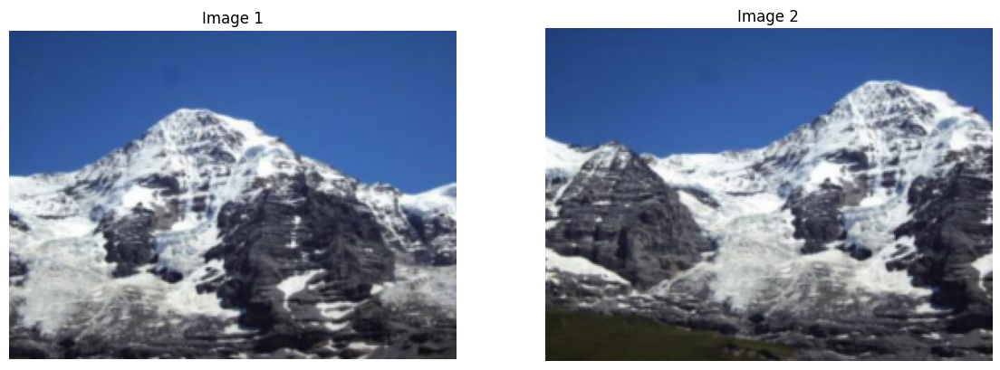

Image 1 size: (193, 262, 3)
Image 2 size: (196, 263, 3)


In [ ]:
#Activity 2 — Load the Images(1)

# Change these filenames to your own images
image1_path = "cv.png"
image2_path = "cv2.png"
img1 = cv2.imread(image1_path)
img2 = cv2.imread(image2_path)
if img1 is None or img2 is None:
  raise FileNotFoundError(
  "Could not load one or both images. Check the filenames/path."
  )

# OpenCV loads images as BGR, so convert to RGB for Matplotlib
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)
plt.title("Image 1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(img2_rgb)
plt.title("Image 2")
plt.axis("off")
plt.show()
print("Image 1 size:", img1.shape)
print("Image 2 size:", img2.shape)



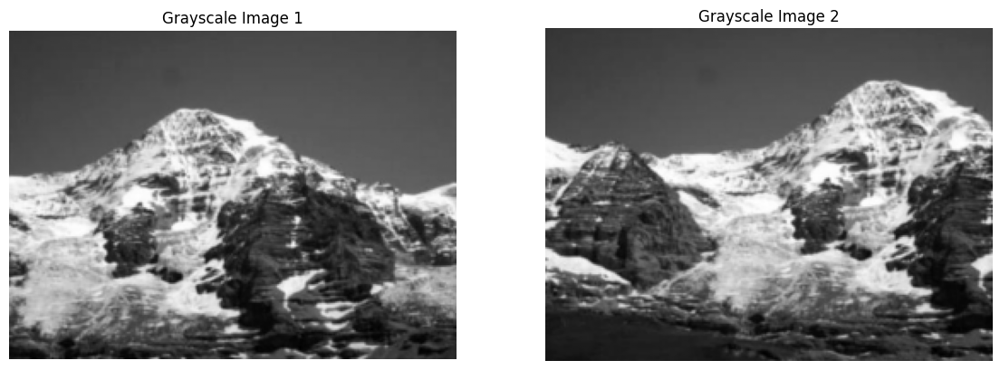

In [ ]:
#Activity 3 — Convert Images to Grayscale(2)
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Grayscale Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray2, cmap="gray")
plt.title("Grayscale Image 2")
plt.axis("off")
plt.show()

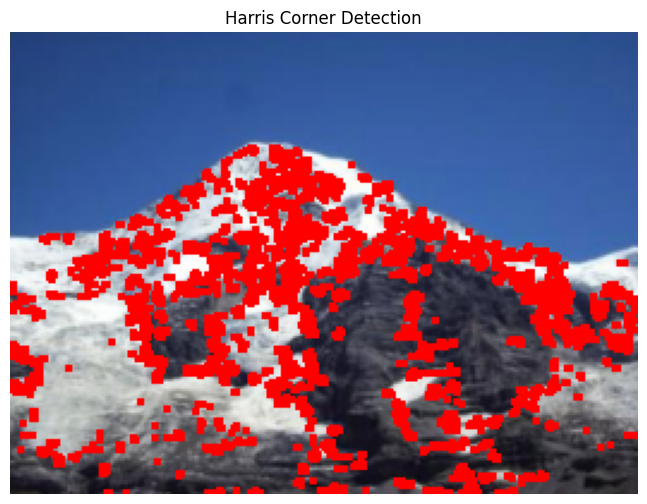

In [ ]:
#Activity 4 — Harris Corner Detection
# Convert to float32 because cv2.cornerHarris expects this type
gray1_float = np.float32(gray1)
# Harris parameters
block_size = 2
kernel_size = 3
k = 0.04
harris_response = cv2.cornerHarris(
  gray1_float,
  block_size,
  kernel_size,
  k
)
# Dilate the response so detected corner regions become larger and easier to see
harris_response = cv2.dilate(harris_response, None)
# Keep pixels whose Harris response is greater than 1% of the maximum response in the image.
# This controls how strong a response must be to be considered a detected corner.
threshold = 0.01 * harris_response.max()

harris_img = img1_rgb.copy()
harris_img[harris_response > threshold] = [255, 0, 0]
plt.figure(figsize=(9, 6))
plt.imshow(harris_img)
plt.title("Harris Corner Detection")
plt.axis("off")
plt.show()

In [ ]:
#Activity 5 — Detect SIFT Keypoints(3)
sift = cv2.SIFT_create()
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)
print("Number of keypoints in Image 1:", len(keypoints1))
print("Number of keypoints in Image 2:", len(keypoints2))
print("Descriptor shape for Image 1:", descriptors1.shape)
print("Descriptor shape for Image 2:", descriptors2.shape)

Number of keypoints in Image 1: 695
Number of keypoints in Image 2: 774
Descriptor shape for Image 1: (695, 128)
Descriptor shape for Image 2: (774, 128)


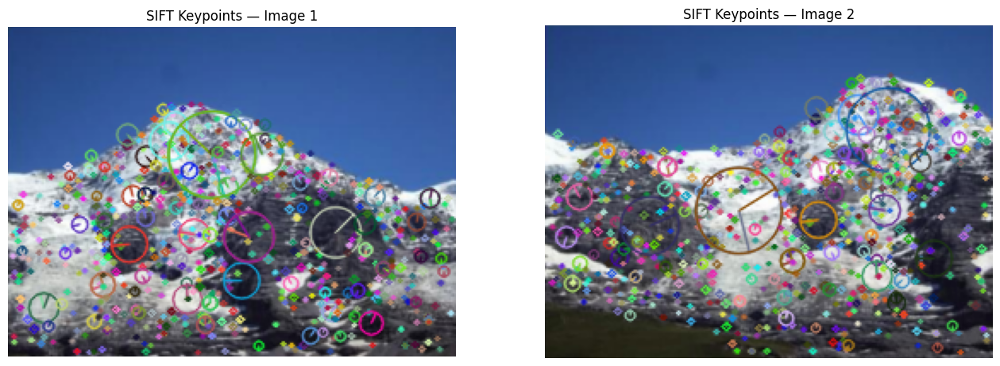

In [ ]:
# Visualize SIFT keypoints
sift_vis1 = cv2.drawKeypoints(
  img1_rgb,
  keypoints1,
  None, # telling OpenCV to create the output image itself
  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
sift_vis2 = cv2.drawKeypoints(
  img2_rgb,
  keypoints2,
  None,
  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(16, 7))
# (rows, columns, position)
plt.subplot(1, 2, 1)
plt.imshow(sift_vis1)
plt.title("SIFT Keypoints — Image 1")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sift_vis2)
plt.title("SIFT Keypoints — Image 2")
plt.axis("off")
plt.show()

In [ ]:
#Activity 6 — Inspect a SIFT Descriptor
# Inspect the first keypoint and its descriptor
print("First keypoint:")
print(keypoints1[0])
print("\nFirst descriptor:")
print(descriptors1[0])
print("\nDescriptor length:")
print(len(descriptors1[0]))

First keypoint:
< cv2.KeyPoint 0x7897bc951110>

First descriptor:
[  0.   0.   0.   0.   0.   0.   0.   0.   1.   0.   0.   0.   0.   1.
   6.   2.  38.   3.   0.   0.   0.   2.  14.  19.  99.  24.   0.   0.
   0.   0.   0.  11.  72.   4.   0.   0.   0.   0.   0.   6. 133.  16.
   1.   1.   0.   5.  40.  59.  94.   6.   2.   3.   3.  16.  96. 102.
 133.   9.   0.   0.   0.   0.   2.  89. 113.  41.  11.   0.   0.   0.
   0.  12. 133. 133.  21.   2.   1.   1.   2.  13. 133.  66.  16.  10.
   3.   4.   6.  51. 133.   2.   0.   0.   0.   3.   7.  63.  17.  43.
  45.   4.   0.   0.   0.   0. 133.  99.  21.   2.   0.   0.   0.  17.
 133.  31.   0.   0.   0.   0.   0.  73. 111.  22.   2.   0.   0.   1.
   1.  30.]

Descriptor length:
128


In [ ]:
#Activity 7 — Match SIFT Descriptors
# Create a Brute-Force matcher
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
# Find the two nearest neighbors for every descriptor
matches_knn = bf.knnMatch(descriptors1, descriptors2, k=2)
print("Number of descriptor pairs examined:", len(matches_knn))

Number of descriptor pairs examined: 695


Total candidate matches: 695
Good matches after ratio test: 348


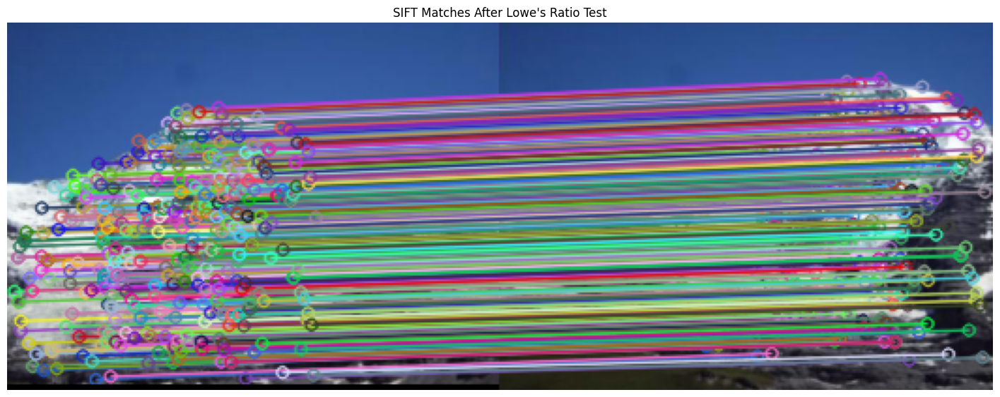

In [ ]:
#Activity 8 — Lowe’s Ratio Test(4)
ratio_threshold = 0.75
good_matches = []
for pair in matches_knn:

  if len(pair) == 2:
    m, n = pair
  if m.distance < ratio_threshold * n.distance:
    good_matches.append(m)
print("Total candidate matches:", len(matches_knn))
print("Good matches after ratio test:", len(good_matches))

# Visualize the good matches
match_img = cv2.drawMatches(
img1_rgb,
keypoints1,
img2_rgb,
keypoints2,
good_matches,
None,
flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(18, 8))
plt.imshow(match_img)
plt.title("SIFT Matches After Lowe's Ratio Test")
plt.axis("off")
plt.show()

In [ ]:
#Activity 9 — Prepare Corresponding Points
if len(good_matches) < 4:

  raise ValueError(
  "At least 4 good matches are required to estimate a homography."
  )
# m.queryIdx → index of the matched keypoint in Image 1
# keypoints1[...] → gets that particular SIFT keypoint
# .pt → gets its pixel coordinates (x, y)
src_pts = np.float32([
keypoints1[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)
dst_pts = np.float32([
keypoints2[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)
print("Source point array shape:", src_pts.shape)
print("Destination point array shape:", dst_pts.shape)

Source point array shape: (348, 1, 2)
Destination point array shape: (348, 1, 2)


In [ ]:
#Activity 10 — Estimate Homography Using RANSAC(5)

# Compute the homography matrix and mask using RANSAC
H, mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    5.0  # maximum allowed reprojection error (in pixels)
)

if H is None:
    raise RuntimeError("Homography could not be estimated.")

# Convert from 1 Column array [[1], [0], [1], ...] to 1D array [1, 0, 1, ...]
mask = mask.ravel()

inlier_matches = [
    # An inlier is a match that agrees with the estimated homography
    match for match, keep in zip(good_matches, mask) if keep
]

outlier_matches = [
    # An outlier does not agree sufficiently with the estimated homography
    match for match, keep in zip(good_matches, mask) if not keep
]

print("Total good matches:", len(good_matches))
print("RANSAC inliers:", len(inlier_matches))
print("RANSAC outliers:", len(outlier_matches))
print("Inlier ratio:", len(inlier_matches) / len(good_matches))
print("\nHomography matrix:\n", H)


Total good matches: 348
RANSAC inliers: 348
RANSAC outliers: 0
Inlier ratio: 1.0

Homography matrix:
 [[ 9.19396261e-01  1.86655191e-02  8.94678934e+01]
 [-4.84746184e-02  1.00034029e+00 -1.13328690e+01]
 [-4.25378076e-04  7.03865283e-05  1.00000000e+00]]


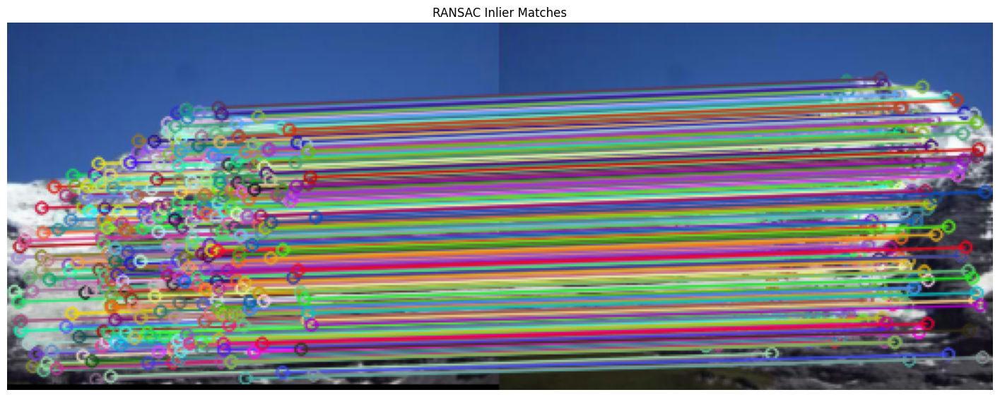

In [ ]:
#Activity 11 — Visualize RANSAC Inliers
# Draw the inlier matches
inlier_img = cv2.drawMatches(
    img1_rgb,
    keypoints1,
    img2_rgb,
    keypoints2,
    inlier_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Plot the result
plt.figure(figsize=(18, 8))
plt.imshow(inlier_img)
plt.title("RANSAC Inlier Matches")
plt.axis("off")
plt.show()


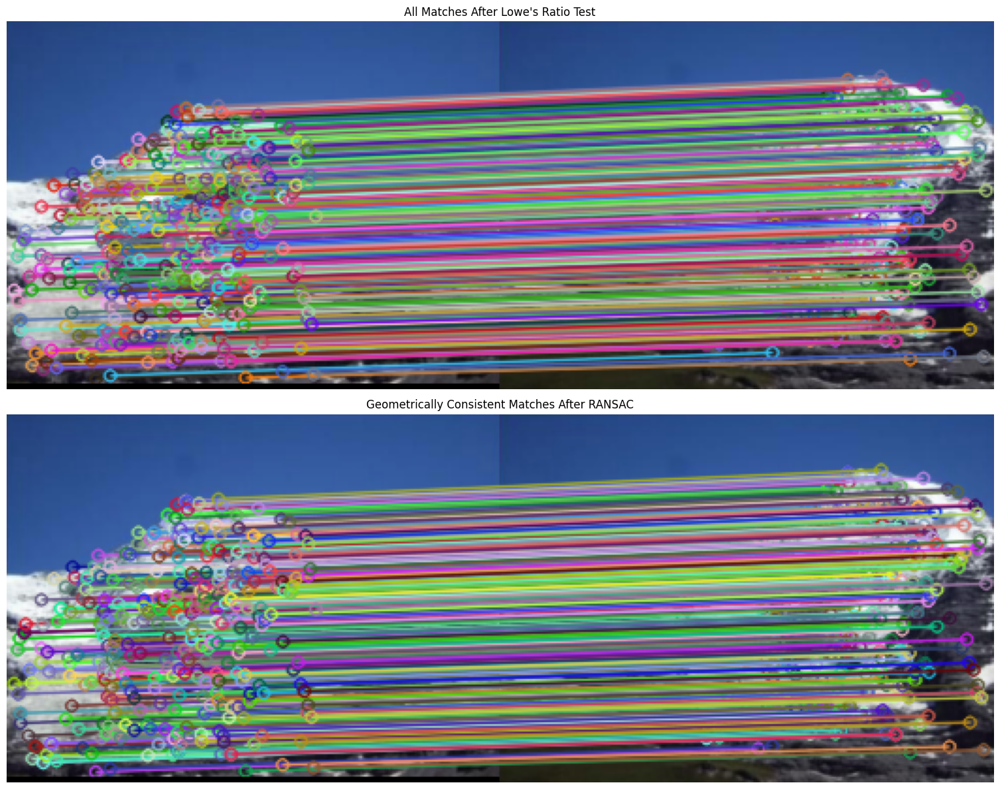

In [ ]:
#Activity 12 — Compare All Matches with RANSAC Inliers
# Create the figure for side-by-side subplot visualization
plt.figure(figsize=(18, 12))

# Subplot 1: All initial good matches
plt.subplot(2, 1, 1)
all_matches_img = cv2.drawMatches(
    img1_rgb,
    keypoints1,
    img2_rgb,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(all_matches_img)
plt.title("All Matches After Lowe's Ratio Test")
plt.axis("off")

# Subplot 2: RANSAC inlier matches only
plt.subplot(2, 1, 2)
inlier_matches_img = cv2.drawMatches(
    img1_rgb,
    keypoints1,
    img2_rgb,
    keypoints2,
    inlier_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.imshow(inlier_matches_img)
plt.title("Geometrically Consistent Matches After RANSAC")
plt.axis("off")

# Clean up layout and display
plt.tight_layout()
plt.show()


HOG feature vector shape: (25668,)
Number of HOG features: 25668


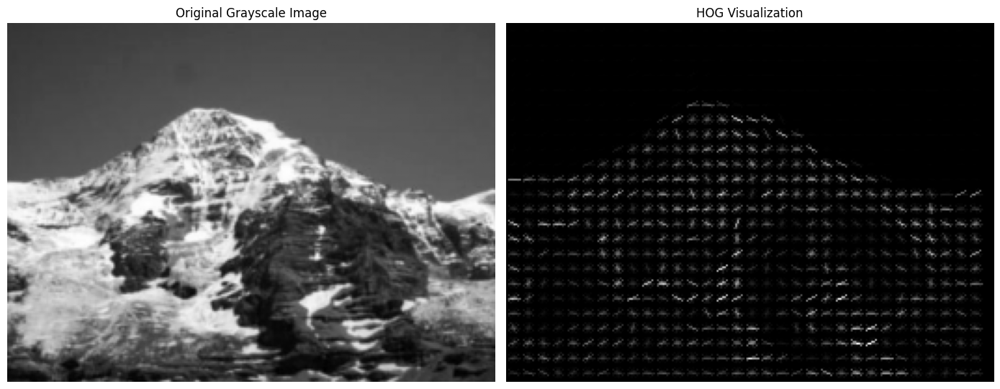

In [ ]:
#Activity 13 — HOG (Histogram of Oriented Gradients)(6)

# Compute HOG features for Image 1
hog_features, hog_image = hog(
    gray1,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
)

print("HOG feature vector shape:", hog_features.shape)
print("Number of HOG features:", len(hog_features))

# Plot the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()


Configuration 1 feature length: 25668
Configuration 2 feature length: 7920


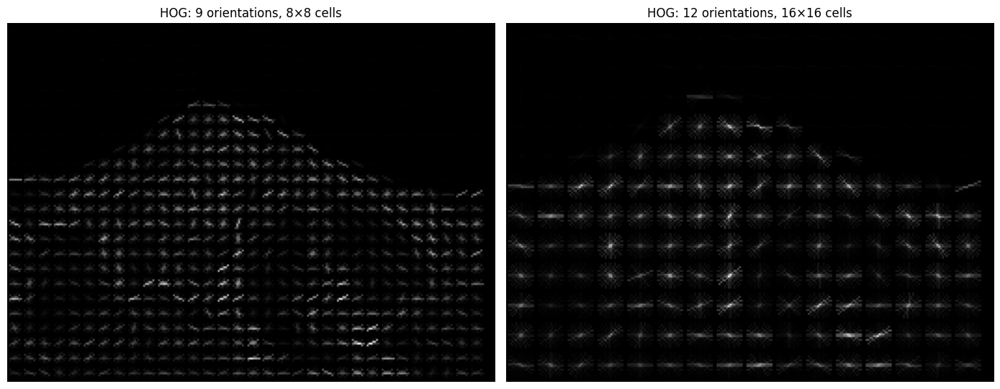

In [ ]:
#Activity 14 — HOG Parameter Experiment
# Compare a second HOG configuration.
hog_features_2, hog_image_2 = hog(
    gray1,
    orientations=12,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
)

print("Configuration 1 feature length:", len(hog_features))
print("Configuration 2 feature length:", len(hog_features_2))

# Plot the comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG: 9 orientations, 8×8 cells")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image_2, cmap="gray")
plt.title("HOG: 12 orientations, 16×16 cells")
plt.axis("off")

plt.tight_layout()
plt.show()


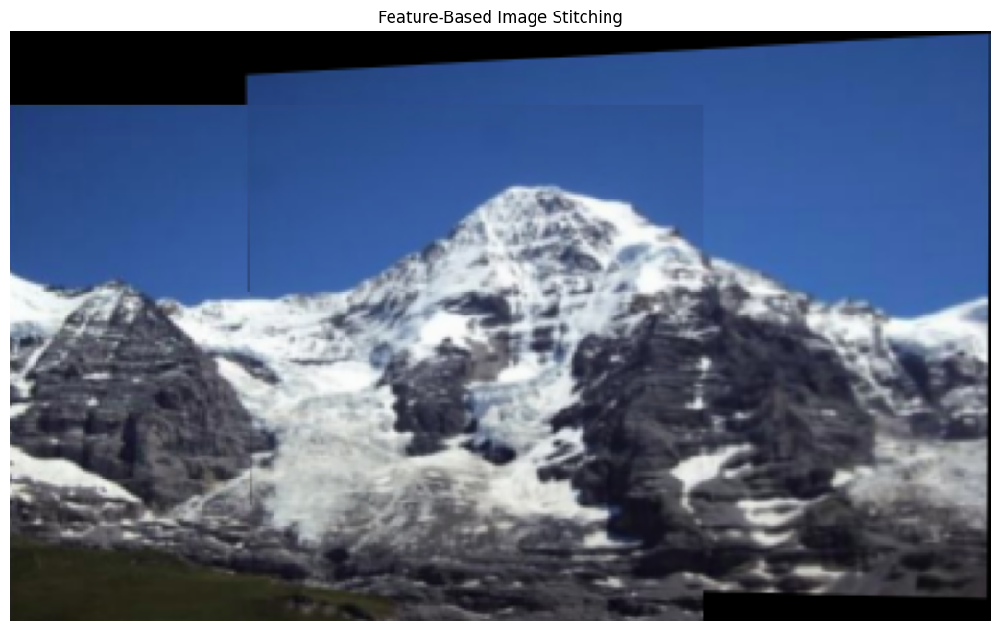

In [ ]:
#Activity 15 — Application: Image Stitching(7)
def simple_feature_stitch(image1, image2, homography):
    # Homography maps points from image1 -> image2.
    # Therefore we warp image1 into image2's coordinate system.

    # Get the height and width of both images
    h1, w1 = image1.shape[:2]
    h2, w2 = image2.shape[:2]

    # Define the four corner coordinates of Image 1
    corners1 = np.float32([[0, 0], [w1, 0], [w1, h1], [0, h1]]).reshape(-1, 1, 2)

    # Define the four corner coordinates of Image 2
    corners2 = np.float32([[0, 0], [w2, 0], [w2, h2], [0, h2]]).reshape(-1, 1, 2)

    # This tells us where Image 1's corners will be located in Image 2's coordinate system
    warped_corners1 = cv2.perspectiveTransform(corners1, homography)

    # Combine the corners of both images to determine the complete size of the panorama canvas
    all_corners = np.concatenate([corners2, warped_corners1], axis=0)

    # Find the minimum x and y coordinates required by the panorama
    # floor() ensures the canvas starts far enough to contain all pixels
    xmin, ymin = np.floor(all_corners.min(axis=0).ravel()).astype(int)

    # Find the maximum x and y coordinates required by the panorama
    # ceil() ensures the canvas is large enough to contain all pixels
    xmax, ymax = np.ceil(all_corners.max(axis=0).ravel()).astype(int)

    # Calculate how much the entire panorama needs to be shifted
    # so that negative coordinates become valid canvas coordinates
    tx, ty = -xmin, -ymin
    translation = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float64)

    # Calculate the width and height of the final panorama canvas
    canvas_w = int(xmax - xmin)
    canvas_h = int(ymax - ymin)

    # Warp image 1 into image 2's coordinate system.
    warped1 = cv2.warpPerspective(
        image1, translation @ homography, (canvas_w, canvas_h)
    )

    # Place image 2 on the same canvas.
    panorama = warped1.copy()

    # from ty up to ty + h2, ty is how far to shift in the y-direction, Height of Img 2 (h2)
    panorama[ty : ty + h2, tx : tx + w2] = image2

    # Simple overlap blending instead of a hard overwrite.
    warped_mask = cv2.warpPerspective(
        np.ones((h1, w1), dtype=np.uint8),
        translation @ homography,
        (canvas_w, canvas_h),
    )
    image2_mask = np.zeros((canvas_h, canvas_w), dtype=np.uint8)
    image2_mask[ty : ty + h2, tx : tx + w2] = 1
    overlap = (warped_mask > 0) & (image2_mask > 0)

    # Average the overlap to make the educational result less abrupt.
    image2_canvas = np.zeros_like(panorama)
    image2_canvas[ty : ty + h2, tx : tx + w2] = image2

    # Instead of abruptly replacing one image with the other, the overlapping area is blended:
    # 50% Image 1 + 50% Image 2
    panorama[overlap] = (
        0.5 * warped1[overlap] + 0.5 * image2_canvas[overlap]
    ).astype(np.uint8)

    # Fill regions containing only image 2.
    only_image2 = (warped_mask == 0) & (image2_mask > 0)
    panorama[only_image2] = image2_canvas[only_image2]

    return panorama


# Reuse the homography already estimated above.
# (Outside the function block, so it returns to 0 indentation)
panorama = simple_feature_stitch(img1, img2, H)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title("Feature-Based Image Stitching")
plt.axis("off")
plt.show()


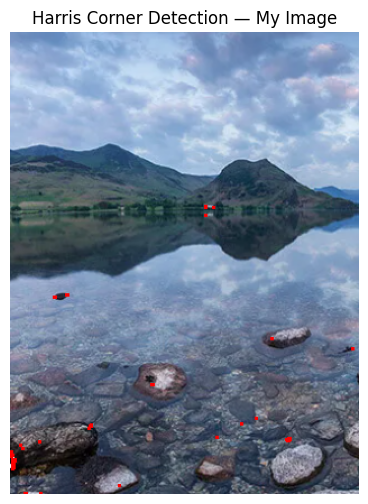

In [ ]:
#lab task 1
# Load your own image
image_path = "cv3.png"

img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError("Check the image path and filename.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Harris parameters
gray_float = np.float32(gray)
block_size = 2
kernel_size = 3
k = 0.04

harris_response = cv2.cornerHarris(
    gray_float, block_size, kernel_size, k
)

harris_response = cv2.dilate(harris_response, None)

# Original lab threshold: 1% of the maximum response
threshold = 0.01 * harris_response.max()

harris_img = img_rgb.copy()
harris_img[harris_response > threshold] = [255, 0, 0]

plt.figure(figsize=(9, 6))
plt.imshow(harris_img)
plt.title("Harris Corner Detection — My Image")
plt.axis("off")
plt.show()

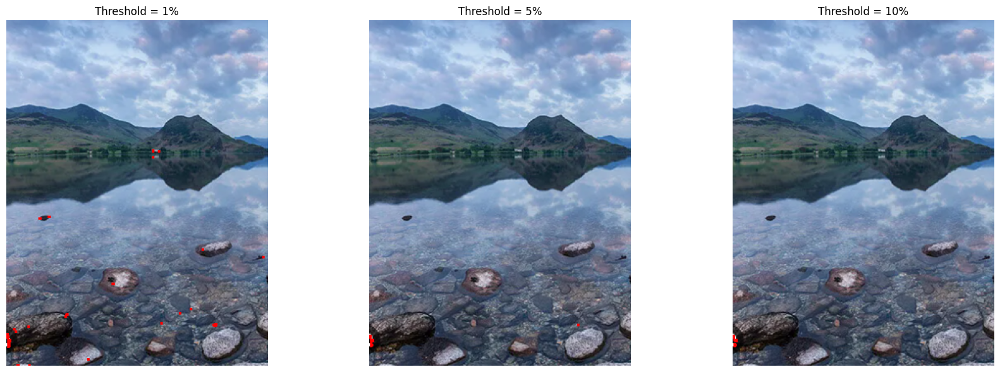

In [ ]:
# Compare three threshold percentages
threshold_percentages = [1, 5, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, percentage in zip(axes, threshold_percentages):
    threshold = (percentage / 100) * harris_response.max()

    result = img_rgb.copy()
    result[harris_response > threshold] = [255, 0, 0]

    ax.imshow(result)
    ax.set_title(f"Threshold = {percentage}%")
    ax.axis("off")

plt.tight_layout()
plt.show()

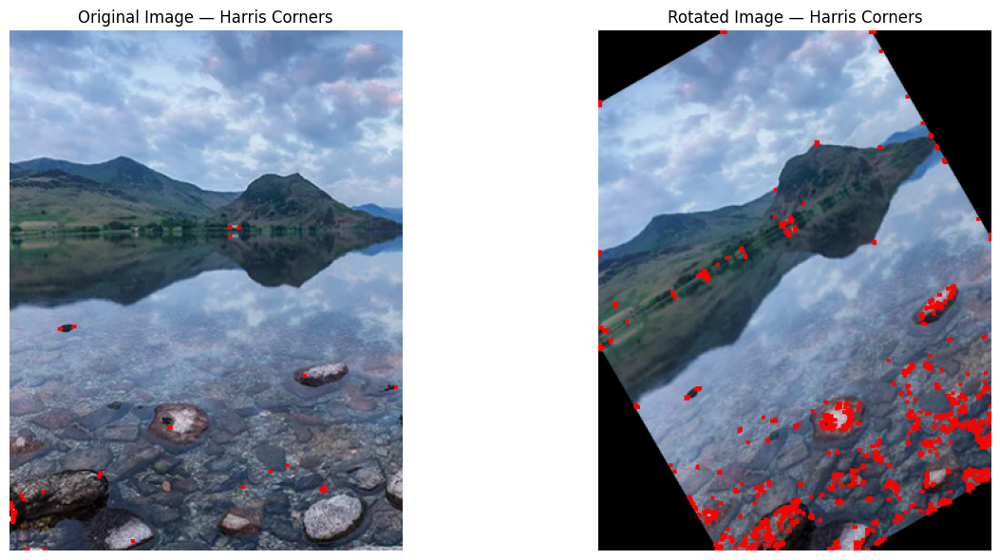

In [ ]:
height, width = gray.shape

# Rotate the image by 30 degrees
rotation_matrix = cv2.getRotationMatrix2D(
    (width / 2, height / 2),
    30,
    1.0
)

rotated = cv2.warpAffine(
    img,
    rotation_matrix,
    (width, height)
)

rotated_rgb = cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)
rotated_gray = cv2.cvtColor(rotated, cv2.COLOR_BGR2GRAY)

# Apply the same Harris parameters
rotated_response = cv2.cornerHarris(
    np.float32(rotated_gray),
    block_size,
    kernel_size,
    k
)

rotated_response = cv2.dilate(rotated_response, None)

rotated_threshold = 0.01 * rotated_response.max()

rotated_result = rotated_rgb.copy()
rotated_result[rotated_response > rotated_threshold] = [255, 0, 0]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(harris_img)
plt.title("Original Image — Harris Corners")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_result)
plt.title("Rotated Image — Harris Corners")
plt.axis("off")

plt.tight_layout()
plt.show()

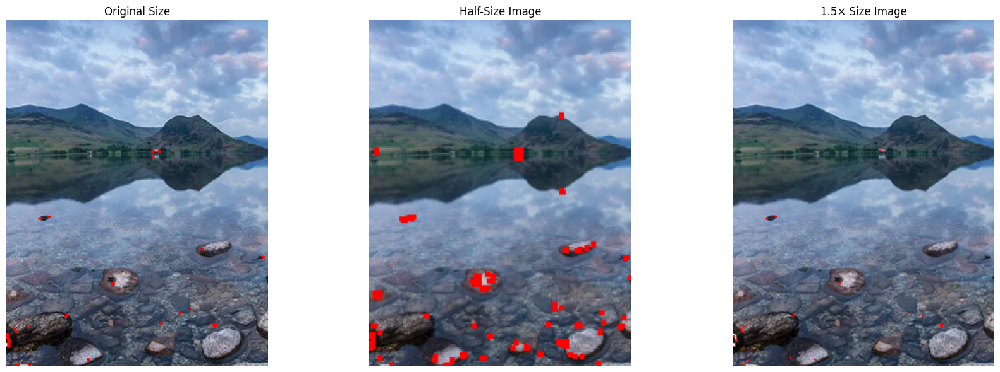

In [ ]:
# Resize to half-size and 1.5 times the original size
small = cv2.resize(img, None, fx=0.5, fy=0.5)
large = cv2.resize(img, None, fx=1.5, fy=1.5)

def detect_harris(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    response = cv2.cornerHarris(
        np.float32(gray_image),
        block_size,
        kernel_size,
        k
    )

    response = cv2.dilate(response, None)
    threshold = 0.01 * response.max()

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_rgb[response > threshold] = [255, 0, 0]

    return image_rgb

small_result = detect_harris(small)
large_result = detect_harris(large)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(harris_img)
plt.title("Original Size")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(small_result)
plt.title("Half-Size Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(large_result)
plt.title("1.5× Size Image")
plt.axis("off")

plt.tight_layout()
plt.show()

We tested different threshold levels at 1%, 5%, and 10% of the maximum Harris response. Setting a higher threshold naturally filters out the noise, leaving behind fewer but much stronger corner detections.
To test the detector's limits, we also rotated the image by 30 degrees and scaled it to 0.5× and 1.5× its original size. While the algorithm handles rotation well, changing the size shifts the pixel structures. Because the Harris detector relies on a fixed-size window to analyze neighborhoods, resizing alters how it sees those pixels. This confirms that the Harris corner detector is not scale-invariant.


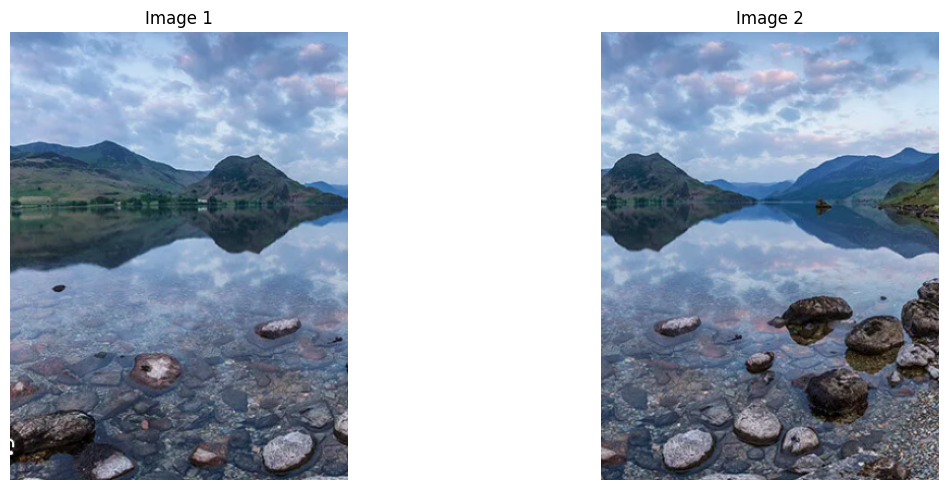

Image 1 size: (412, 311, 3)
Image 2 size: (412, 311, 3)


In [ ]:
#lab task 2

image1_path = "cv3.png"
image2_path = "cv4.png"

img1 = cv2.imread(image1_path)
img2 = cv2.imread(image2_path)

if img1 is None or img2 is None:
    raise FileNotFoundError(
        "Could not load one or both images. Check the filenames/path."
    )

img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1_rgb)
plt.title("Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2_rgb)
plt.title("Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image 1 size:", img1.shape)
print("Image 2 size:", img2.shape)

In [ ]:
sift = cv2.SIFT_create()

keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

print("Number of keypoints in Image 1:", len(keypoints1))
print("Number of keypoints in Image 2:", len(keypoints2))
print("Descriptor shape for Image 1:", descriptors1.shape)
print("Descriptor shape for Image 2:", descriptors2.shape)

Number of keypoints in Image 1: 798
Number of keypoints in Image 2: 968
Descriptor shape for Image 1: (798, 128)
Descriptor shape for Image 2: (968, 128)


Total candidate matches: 798
Good matches after ratio test: 344


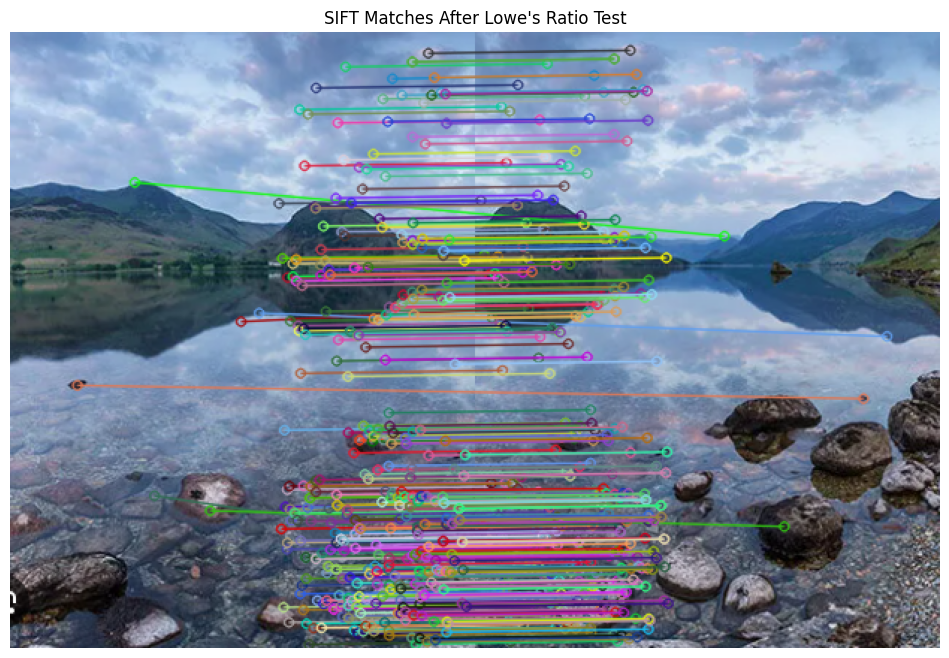

In [ ]:
# Brute-force matching using Euclidean distance
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Find the two nearest candidate matches
matches_knn = bf.knnMatch(descriptors1, descriptors2, k=2)

# Lowe's ratio test — threshold from Lab 06
ratio_threshold = 0.75
good_matches = []

for pair in matches_knn:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_matches.append(m)

print("Total candidate matches:", len(matches_knn))
print("Good matches after ratio test:", len(good_matches))

# Display accepted matches
match_img = cv2.drawMatches(
    img1_rgb,
    keypoints1,
    img2_rgb,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(match_img)
plt.title("SIFT Matches After Lowe's Ratio Test")
plt.axis("off")
plt.show()

In [ ]:
# At least four correspondences are needed for homography estimation
if len(good_matches) < 4:
    raise ValueError(
        "At least 4 good matches are required to estimate a homography."
    )

# Coordinates from Image 1
src_pts = np.float32([
    keypoints1[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

# Corresponding coordinates from Image 2
dst_pts = np.float32([
    keypoints2[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

# Estimate homography using the RANSAC threshold from Lab 06
H, mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    5.0
)

if H is None or mask is None:
    raise RuntimeError("Homography could not be estimated.")

mask = mask.ravel()

inlier_matches = [
    match for match, keep in zip(good_matches, mask) if keep
]

outlier_matches = [
    match for match, keep in zip(good_matches, mask) if not keep
]

inlier_count = len(inlier_matches)
outlier_count = len(outlier_matches)

print("Total good matches:", len(good_matches))
print("RANSAC inlier count:", inlier_count)
print("RANSAC outlier count:", outlier_count)
print("Inlier ratio:", inlier_count / len(good_matches))
print("Homography matrix:\n", H)

Total good matches: 344
RANSAC inlier count: 338
RANSAC outlier count: 6
Inlier ratio: 0.9825581395348837
Homography matrix:
 [[ 9.99959996e-01 -6.08272395e-05 -1.75964894e+02]
 [ 1.08163026e-04  9.99999951e-01 -2.02255123e+00]
 [ 2.73638508e-07 -1.48299718e-07  1.00000000e+00]]


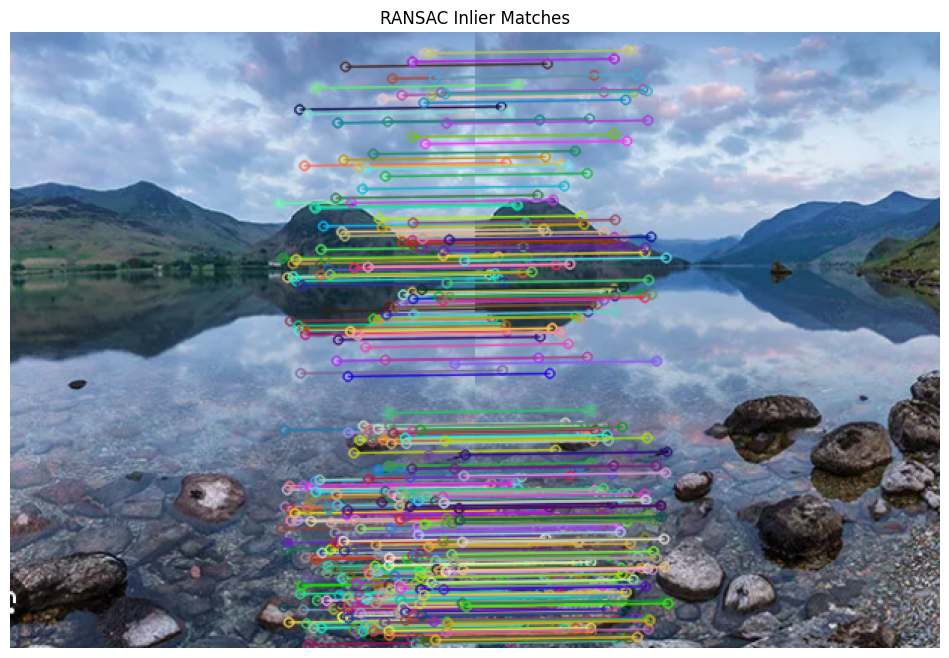

In [ ]:
inlier_img = cv2.drawMatches(
    img1_rgb,
    keypoints1,
    img2_rgb,
    keypoints2,
    inlier_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(inlier_img)
plt.title("RANSAC Inlier Matches")
plt.axis("off")
plt.show()

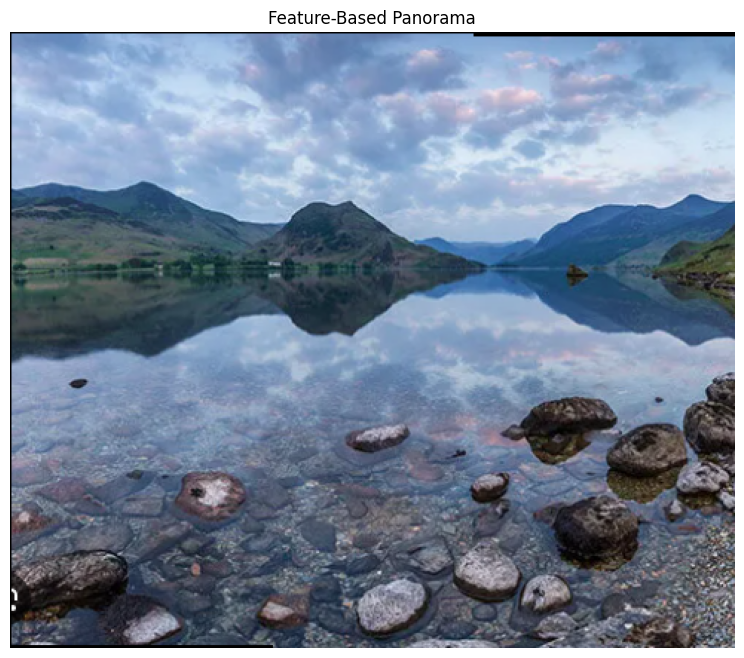

In [ ]:
def simple_feature_stitch(image1, image2, homography):
    # Get image dimensions
    h1, w1 = image1.shape[:2]
    h2, w2 = image2.shape[:2]

    # Four corners of Image 1
    corners1 = np.float32([
        [0, 0], [w1, 0], [w1, h1], [0, h1]
    ]).reshape(-1, 1, 2)

    # Four corners of Image 2
    corners2 = np.float32([
        [0, 0], [w2, 0], [w2, h2], [0, h2]
    ]).reshape(-1, 1, 2)

    # Transform Image 1's corners
    warped_corners1 = cv2.perspectiveTransform(
        corners1, homography
    )

    # Calculate panorama boundaries
    all_corners = np.concatenate(
        [corners2, warped_corners1], axis=0
    )

    xmin, ymin = np.floor(
        all_corners.min(axis=0).ravel()
    ).astype(int)

    xmax, ymax = np.ceil(
        all_corners.max(axis=0).ravel()
    ).astype(int)

    # Translation to avoid negative coordinates
    tx, ty = -xmin, -ymin

    translation = np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=np.float64)

    canvas_w = int(xmax - xmin)
    canvas_h = int(ymax - ymin)

    # Warp Image 1 into the panorama canvas
    warped1 = cv2.warpPerspective(
        image1,
        translation @ homography,
        (canvas_w, canvas_h)
    )

    # Place Image 2 on the same canvas
    panorama = warped1.copy()
    panorama[ty:ty + h2, tx:tx + w2] = image2

    # Mask showing where warped Image 1 exists
    warped_mask = cv2.warpPerspective(
        np.ones((h1, w1), dtype=np.uint8),
        translation @ homography,
        (canvas_w, canvas_h)
    )

    # Mask showing where Image 2 exists
    image2_mask = np.zeros(
        (canvas_h, canvas_w), dtype=np.uint8
    )
    image2_mask[ty:ty + h2, tx:tx + w2] = 1

    # Identify overlap
    overlap = (warped_mask > 0) & (image2_mask > 0)

    # Place Image 2 into a separate canvas
    image2_canvas = np.zeros_like(panorama)
    image2_canvas[ty:ty + h2, tx:tx + w2] = image2

    # Blend overlapping pixels using a 50/50 average
    panorama[overlap] = (
        0.5 * warped1[overlap] +
        0.5 * image2_canvas[overlap]
    ).astype(np.uint8)

    # Copy Image 2 pixels where Image 1 does not exist
    only_image2 = (warped_mask == 0) & (image2_mask > 0)
    panorama[only_image2] = image2_canvas[only_image2]

    return panorama


# Use the homography estimated by RANSAC
panorama = simple_feature_stitch(img1, img2, H)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title("Feature-Based Panorama")
plt.axis("off")
plt.show()

Observation: SIFT descriptors were matched between the overlapping photographs. Lowe's ratio test removed ambiguous matches, and RANSAC identified correspondences consistent with the estimated homography. The homography was then used to align the images and create the panorama.